# 02 · Demografía, construcción y precio de la vivienda

¿Crece la demanda de vivienda más rápido que la oferta? ¿Qué parte del crecimiento de residentes procede de la migración?

Este bloque contrasta afirmaciones descriptivas habituales: **se construye poco**, **la población crece más rápido que las viviendas** y **el crecimiento poblacional procede principalmente de la inmigración**. No parte de que sean ciertas, ni atribuye las declaraciones a políticos concretos sin una cita verificable.

Se reutiliza la **tasación media anual de vivienda libre en €/m²** del notebook 1. El objetivo es 2000–2025; la comparación conjunta empieza en **2001**, primer año del parque publicado. Las otras fuentes conservan su cobertura real.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "data/metadata").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.demographics import (
    load_panels, common_index, annual_change, make_figure, run_analysis
)
pd.set_option("display.max_columns", 20)


## Fuentes, fechas y reglas comunes

| Variable | Fuente | Uso en este bloque |
|---|---|---|
| Precio | MIVAU, snapshot del bloque 1 | Media de cuatro trimestres completos, 2000–2025; nominal |
| Población y adultos | INE ECP 56934 y 59583 | Cierre 2000–2025; 2025 provisional |
| Parque total | MIVAU VDP002_01 | 31 de diciembre, 2001–2025 |
| Viviendas iniciadas y terminadas | MIVAU VDP005_01 | Suma de 12 meses, libres + protegidas, 2008–2025 |
| Hogares nacionales y autonómicos | INE ECP 60135 y 60131 | Cierre 2020–2025; creación neta 2021–2025 |
| Lugar de nacimiento | INE ECP 79276 y 79273 | Cierre 2001–2025; 2025 provisional |
| Saldos y crecimiento demográfico | INE IDB 1416, 5227, 61769 y 5224 | Tasas por 1.000 habitantes, 2008–2024 |

**Alineación:** el cierre del año *t* usa la población y hogares del **1 de enero de t+1**. Una variación de hogares durante 2025 compara enero de 2026 con enero de 2025. El precio sigue siendo una media anual, no un stock de cierre.

Las series definitivas tienen prioridad; solo se añaden fechas posteriores de la publicación provisional. Los hogares ECP y las estimaciones MIVAU pueden revisarse. No se interpolan datos, no se introducen proyecciones y no se usa un segundo eje vertical. Los precios nominales no miden accesibilidad ni crecimiento real: la comparación con IPC está en el bloque 1.

El parque incluye viviendas ocupadas y no principales; **no es oferta disponible para comprar o alquilar**. Un adulto no equivale a un hogar, y un hogar observado no recoge toda la demanda latente de quienes no consiguen emanciparse.

In [2]:
manifest = json.loads((ROOT / "data/snapshots/block02/source_manifest.json").read_text())
sources = pd.DataFrame(manifest["sources"])
display(sources[["name", "url", "units", "release", "retrieved_at_utc", "raw_sha256"]])

# load_panels comprueba SHA-256, edades, cobertura mensual y agregaciones.
annual, birthplace, components, regional = load_panels(ROOT)
coverage = pd.DataFrame([
    {"variable": c, "primer_año": annual[c].first_valid_index(),
     "último_año": annual[c].last_valid_index(), "años_observados": annual[c].notna().sum()}
    for c in ["price", "population", "adults", "dwellings", "households", "completions"]
])
display(coverage)
display(annual.tail(6))

,name,url,units,release,retrieved_at_utc,raw_sha256
0,population,https://www.ine.es/jaxiT3/files/t/csv_bdsc/56934.csv,personas,definitivo,2026-10-06T21:00:49.049007+00:00,2a281cdf6f8262a3596d98990e2c7a1af7a3df048aaad875af6ec7b72a51d08b
1,population_provisional,https://www.ine.es/jaxiT3/files/t/csv_bdsc/59583.csv,personas,provisional,2026-10-06T21:02:31.737776+00:00,09965d6393e131eaabb4147cbe0b129009d6e29e04ff029c28745a586414ee85
2,birthplace,https://www.ine.es/jaxiT3/files/t/csv_bdsc/79276.csv,personas,definitivo,2026-10-06T21:01:12.756414+00:00,8e0b22a883997b5219caaa95ccc4c131eed0e885edffca7fc66175aa1bb5accf
3,birthplace_provisional,https://www.ine.es/jaxiT3/files/t/csv_bdsc/79273.csv,personas,provisional,2026-10-06T21:02:31.248997+00:00,5bf76f4878bfa281c99486d317232a8bd6622b7e29160981b3613b2df980058f
4,households,https://www.ine.es/jaxiT3/files/t/csv_bdsc/60135.csv,hogares,"ECP, puede revisarse",2026-10-06T21:01:12.216214+00:00,e87add00018544a0e979c019fd775ffcb225d2f848db8f54fb9376ddc46b5f2f
5,households_regions,https://www.ine.es/jaxiT3/files/t/csv_bdsc/60131.csv,hogares,"ECP, puede revisarse",2026-10-06T21:01:12.419306+00:00,aa4d45736b03c3d205fef8b76bbfd3366305dbf83c7b291f212088eb58d43dac
6,stock,https://cdn.mivau.gob.es/portal-web-mivau/Datos_MIVAU/CSV/VDP002_01.csv,viviendas,estimación,2026-10-06T21:00:46.226357+00:00,2eda9bafa3f56a5406da5032ab9a10d1de12df9105ff6845e5de9110ff92f7eb
7,construction,https://cdn.mivau.gob.es/portal-web-mivau/Datos_MIVAU/CSV/VDP005_01.csv,viviendas,estimación,2026-10-06T21:01:07.274913+00:00,755ad55f149a47b690e19134239f7aa6faa8c129a89dec572c6d31f561097568
8,natural,https://www.ine.es/jaxiT3/files/t/csv_bdsc/1416.csv,personas por 1.000 habitantes,IDB,2026-10-06T21:01:45.554913+00:00,7164e7a3126f824f5cb07c982fedc81a8b3bdd862c6bd1229a790bc545d9d02d
9,migration_old,https://www.ine.es/jaxiT3/files/t/csv_bdsc/5227.csv,personas por 1.000 habitantes,2008–2020,2026-10-06T21:01:45.002033+00:00,f7a85b56dc4c1f653cf0de6804e07440110297a852c15fe5162c12b8c8efccd3


,variable,primer_año,último_año,años_observados
0,price,2000,2025,26
1,population,2000,2025,26
2,adults,2000,2025,26
3,dwellings,2001,2025,25
4,households,2020,2025,6
5,completions,2008,2025,18


,price,population,adults,population_status,dwellings,households,starts,completions,population_change,net_household_formation,formation_minus_completions,dwellings_per_1000_residents,dwellings_per_1000_adults,price_change_pct,population_change_pct
year,,,,,,,,,,,,,,,
2020,1623.100,47400798.0,39216107.0,definitivo,26623708.0,18539223.0,87907.0,87504.0,82748.0,NaN,NaN,561.672147,678.897270,-1.102852,0.174876
2021,1657.575,47486727.0,39398109.0,definitivo,26719905.0,18822103.0,114293.0,94728.0,85929.0,282880.0,188152.0,562.681547,678.202728,2.124022,0.181282
2022,1740.975,48085361.0,40007177.0,definitivo,26811833.0,19103050.0,110018.0,89545.0,598634.0,280947.0,191402.0,557.588265,670.175579,5.031447,1.260634
2023,1809.075,48619695.0,40594509.0,definitivo,26902443.0,19314630.0,110344.0,89320.0,534334.0,211580.0,122260.0,553.323977,662.711378,3.911601,1.111220
2024,1913.625,49128297.0,41167352.0,definitivo,27004765.0,19521046.0,136187.0,100980.0,508602.0,206416.0,105436.0,549.678427,655.975274,5.779197,1.046082
2025,2127.575,49596376.0,41731209.0,provisional,27099556.0,19762059.0,137330.0,91896.0,468079.0,241013.0,149117.0,546.401939,649.383439,11.180351,0.952769


## 1 · Precio, población y parque: una misma base

Primero comparamos el crecimiento acumulado. Todas las series valen 100 en el primer año **común** del panel; no se permite que cada línea elija su propia base. El segundo panel añade hogares, cuya serie comparable es más corta.

Que las curvas suban a la vez no demuestra que una cause la otra. Una correlación de niveles podría reflejar tendencias compartidas.

,cambio_acumulado_pct
price,120.02
population,20.86
adults,23.93
dwellings,28.84


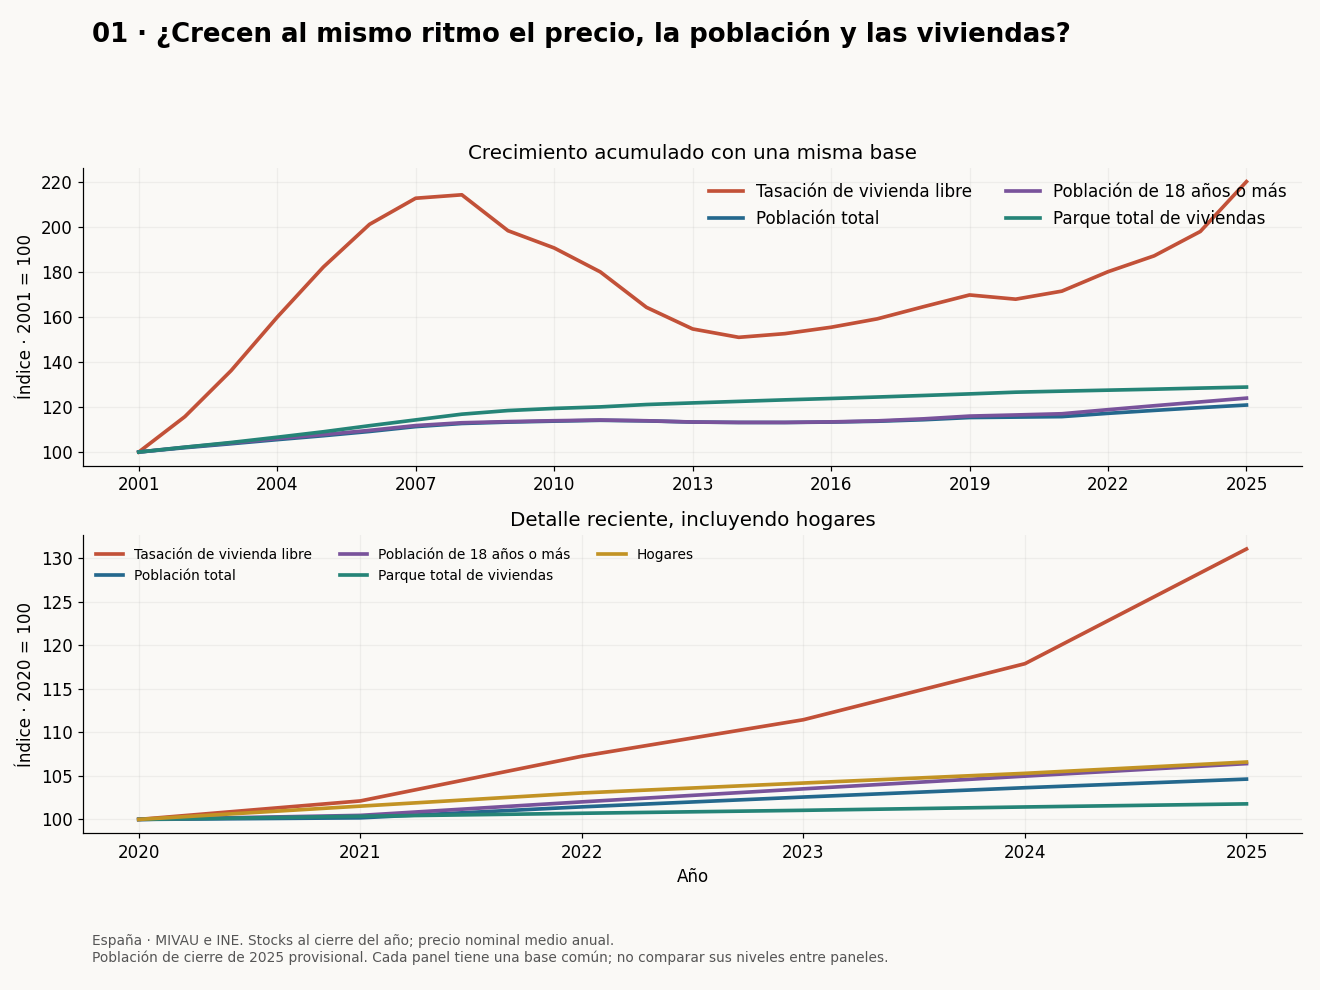

In [3]:
comparison = common_index(annual[["price", "population", "adults", "dwellings"]])
changes = ((comparison.iloc[-1] / comparison.iloc[0] - 1) * 100).rename("cambio_acumulado_pct")
display(changes.to_frame().round(2))
fig = make_figure(1, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## 2 · Viviendas por habitante y por adulto

Las ratios separan el tamaño del parque del crecimiento poblacional. Se muestran en paneles distintos con unidades explícitas y ejes desde cero.

Una caída reciente puede coexistir con una mejora desde 2001. Una ratio nacional tampoco identifica si las viviendas se encuentran donde hay demanda.

,viviendas_por_1000_habitantes,viviendas_por_1000_adultos
year,,
2001,512.58,624.63
2020,561.67,678.90
2025,546.40,649.38


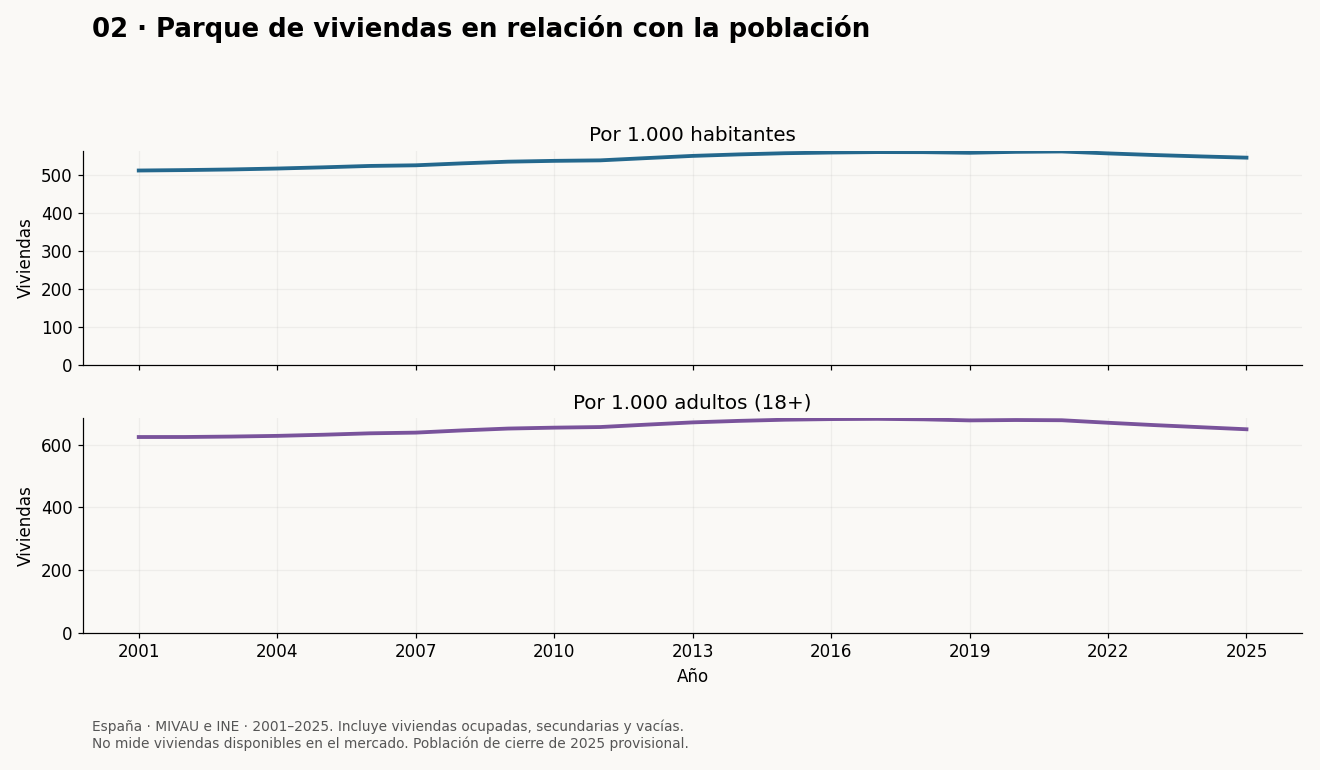

In [4]:
ratios = pd.DataFrame({
    "viviendas_por_1000_habitantes": annual.dwellings / annual.population * 1000,
    "viviendas_por_1000_adultos": annual.dwellings / annual.adults * 1000,
})
display(ratios.loc[[2001, 2020, 2025]].round(2))
fig = make_figure(2, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## 3 · Construcción y creación neta de hogares

El panel superior muestra viviendas iniciadas y terminadas desde 2008. **Iniciadas no significa entregadas**: una obra tarda y puede no finalizar.

El panel inferior compara viviendas terminadas con nuevos hogares observados durante 2021–2025. Los CSV contienen totales nacionales y provincias: se usa el total nacional y se verifica contra las provincias, sin sumar ambos.

La diferencia acumulada es un **indicador de desajuste de flujos**, no una estimación completa del déficit. Puede cubrirse parcialmente ocupando viviendas existentes, rehabilitando o compartiendo; también hay bajas y desigualdad territorial.

,households,completions,starts,nuevos_hogares,hogares_menos_terminadas
year,,,,,
2021,18822103.0,94728.0,114293.0,282880.0,188152.0
2022,19103050.0,89545.0,110018.0,280947.0,191402.0
2023,19314630.0,89320.0,110344.0,211580.0,122260.0
2024,19521046.0,100980.0,136187.0,206416.0,105436.0
2025,19762059.0,91896.0,137330.0,241013.0,149117.0


,acumulado
nuevos_hogares,1222836.0
completions,466469.0
hogares_menos_terminadas,756367.0


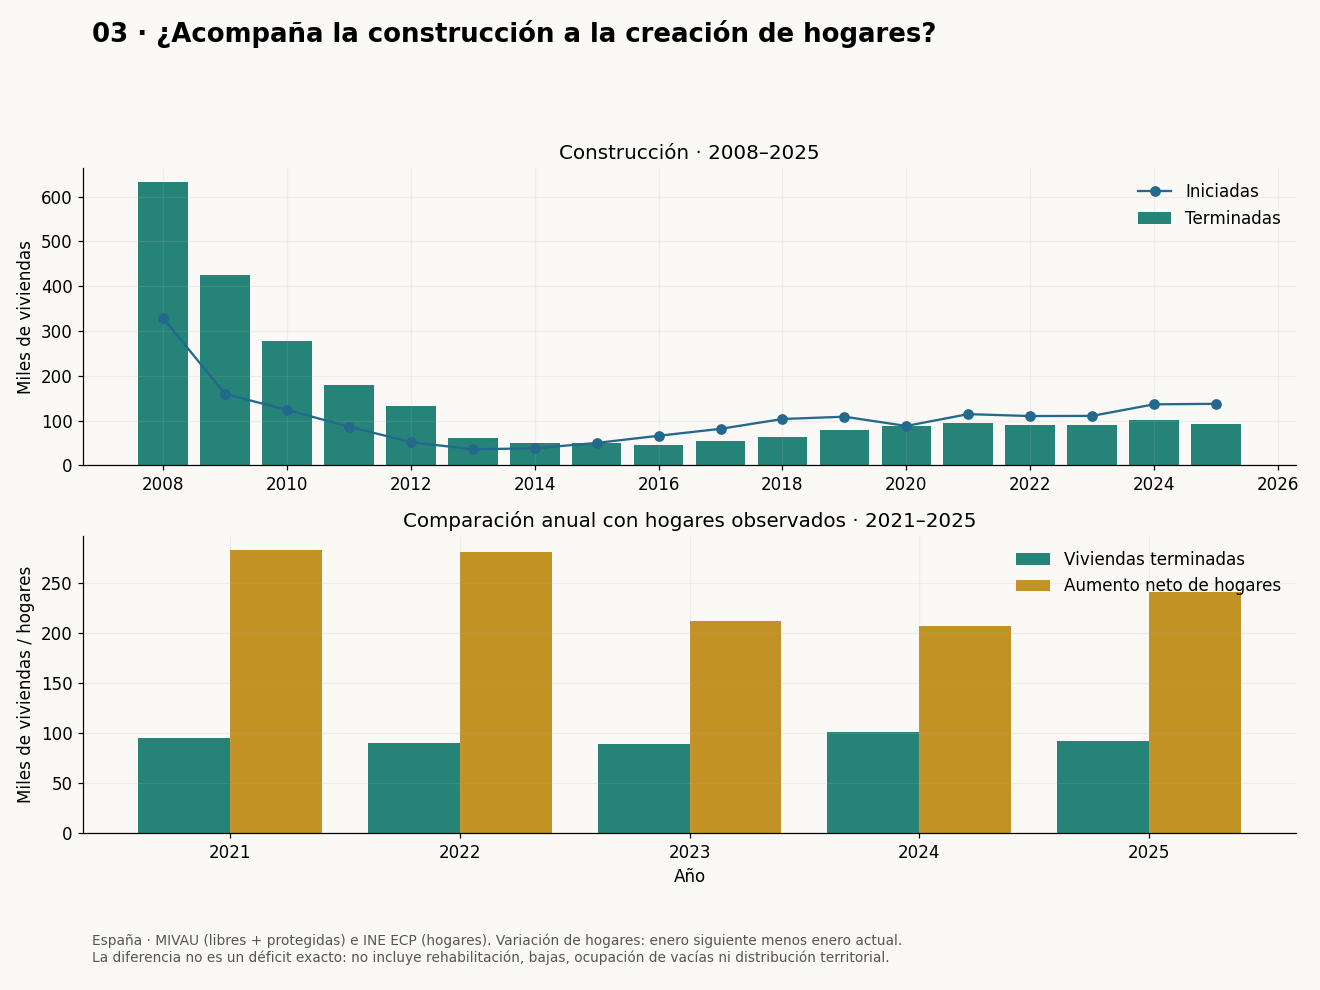

In [5]:
flows = annual[["households", "completions", "starts"]].copy()
flows["nuevos_hogares"] = annual_change(flows.households)
flows["hogares_menos_terminadas"] = flows.nuevos_hogares - flows.completions
joint = flows.dropna(subset=["nuevos_hogares", "completions"])
display(joint.round(0))
display(joint[["nuevos_hogares", "completions", "hogares_menos_terminadas"]].sum().to_frame("acumulado"))
fig = make_figure(3, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## 4 · Nacimientos, defunciones y migración exterior

**Saldo natural = nacimientos − defunciones. Saldo migratorio = entradas − salidas del país.** Ambos incluyen a residentes de cualquier nacionalidad. El saldo natural no equivale a «la gente de aquí» y la migración incluye españoles que regresan o emigran.

Se usan las tasas oficiales por 1.000 habitantes, preservando su precisión publicada. El crecimiento total puede no coincidir exactamente con la suma: se muestra el residuo de las publicaciones y revisiones en lugar de asignarlo a la inmigración. La línea de 2021 marca el cambio de estadística migratoria.

,natural_per_1000,migration_per_1000,growth_per_1000,residual_per_1000
year,,,,
2008,2.92,6.76,12.40,2.72
2009,2.38,0.28,5.33,2.67
2010,2.26,-0.92,3.88,2.54
2011,1.81,-0.81,3.23,2.23
2012,1.12,-3.05,-2.26,-0.33
2013,0.77,-5.40,-4.66,-0.03
2014,0.70,-2.05,-1.51,-0.16
2015,-0.04,-0.04,-0.15,-0.07
2016,0.01,1.88,1.69,-0.20


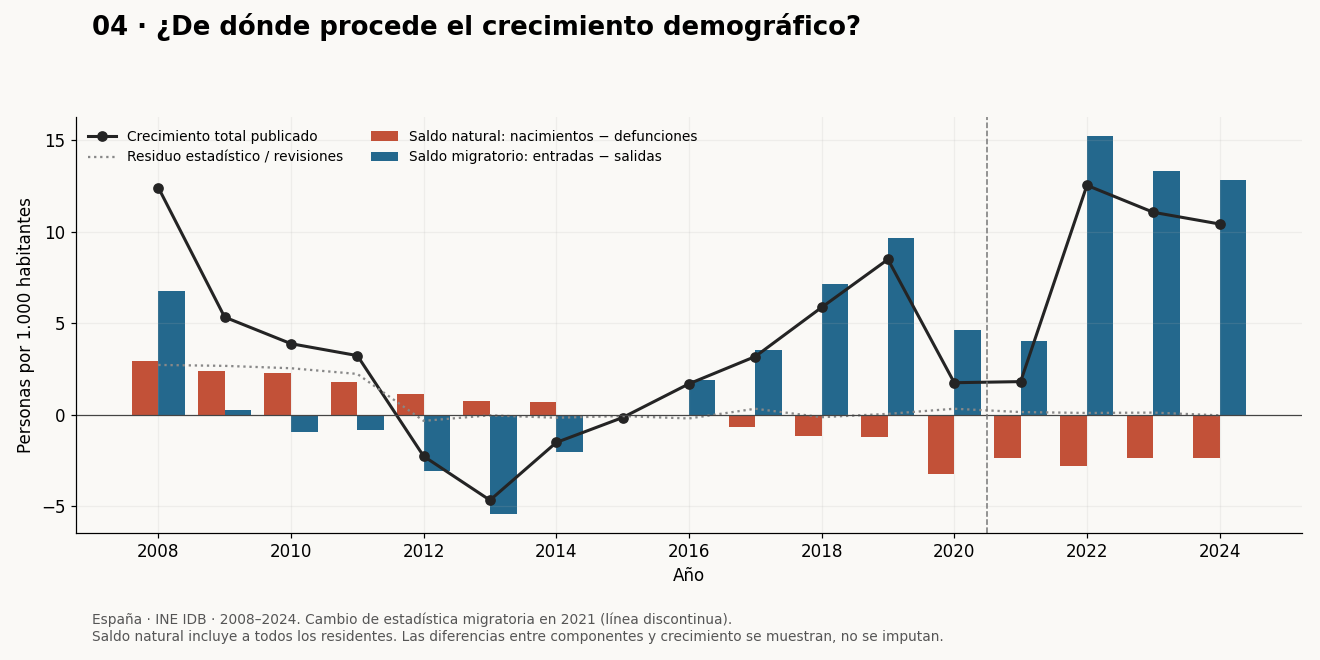

In [6]:
display(components.round(2))
fig = make_figure(4, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## 5 · Residentes nacidos en España y en el extranjero

Esta comparación responde a qué grupos aportan el cambio de población observado. El **lugar de nacimiento** se distingue de la nacionalidad: una persona nacida fuera puede ser española; una nacida en España puede tener nacionalidad extranjera.

El cambio en los nacidos fuera incorpora entradas, salidas y defunciones. El de nacidos en España incorpora además nacimientos. Por eso estas variaciones **no equivalen a flujos migratorios** ni separan toda la historia migratoria de una familia.

En algunos años anteriores a 2012, los recuentos publicados redondeados presentan un residuo de una persona entre grupos y total; se conserva sin reasignarlo.

País de nacimiento,born_spain,born_abroad
year,,
2020,-157296.0,240044.0
2021,-127390.0,213319.0
2022,-137456.0,736090.0
2023,-99694.0,634028.0
2024,-117374.0,625976.0
2025,-104599.0,572678.0


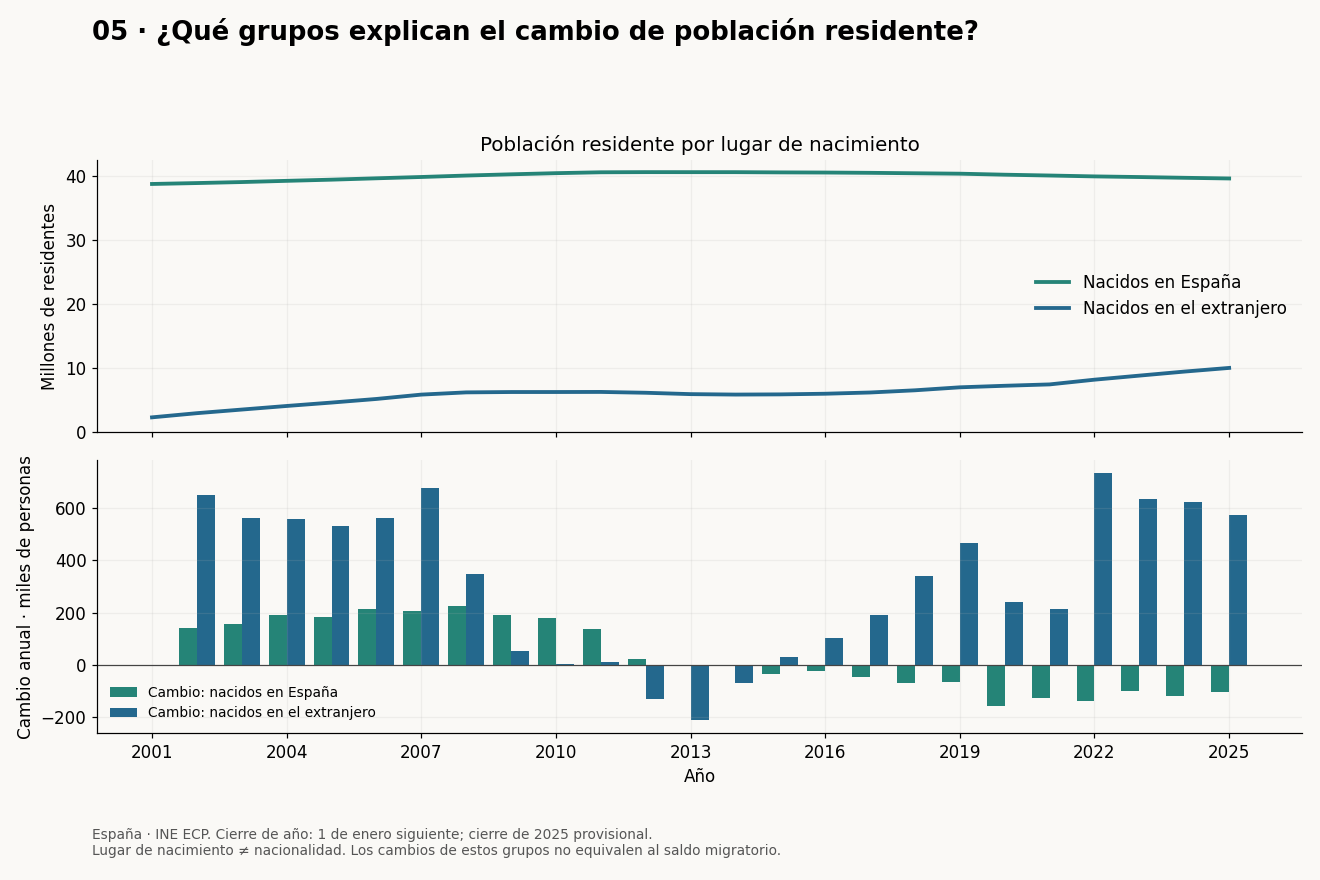

In [7]:
birthplace_changes = birthplace[["born_spain", "born_abroad"]].apply(annual_change)
display(birthplace_changes.tail(6).round(0))
assert ((birthplace.born_spain + birthplace.born_abroad - birthplace.population).abs() <= 1).all()
fig = make_figure(5, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## 6 · Comparación entre comunidades autónomas

Se comparan hogares, parque y precio con **los mismos extremos: 2020–2025**. Las tres columnas comparten escala porcentual y orden regional; así se evita exagerar diferencias mediante ejes distintos.

Se incluyen las 17 comunidades. Ceuta y Melilla se excluyen de esta figura porque el parque se publica como una unidad conjunta, mientras que los hogares están separados. La comparación territorial tampoco demuestra causalidad: actividad económica, migración interior, renta, turismo y financiación pueden relacionarse con estas variables.

,code,start_year,end_year,households_change_pct,dwellings_change_pct,price_change_pct,name
9,10,2020,2025,9.56,1.43,41.61,Comunitat Valenciana
13,14,2020,2025,9.11,1.45,25.15,Región de Murcia
12,13,2020,2025,7.95,3.31,41.62,Comunidad de Madrid
7,8,2020,2025,7.01,1.43,23.08,Castilla-La Mancha
8,9,2020,2025,6.81,1.70,26.67,Cataluña
3,4,2020,2025,6.46,2.35,52.10,Illes Balears
14,15,2020,2025,6.42,3.48,27.06,Navarra
0,1,2020,2025,6.42,1.94,36.39,Andalucía
1,2,2020,2025,6.25,1.49,30.85,Aragón
4,5,2020,2025,6.17,1.24,35.77,Canarias


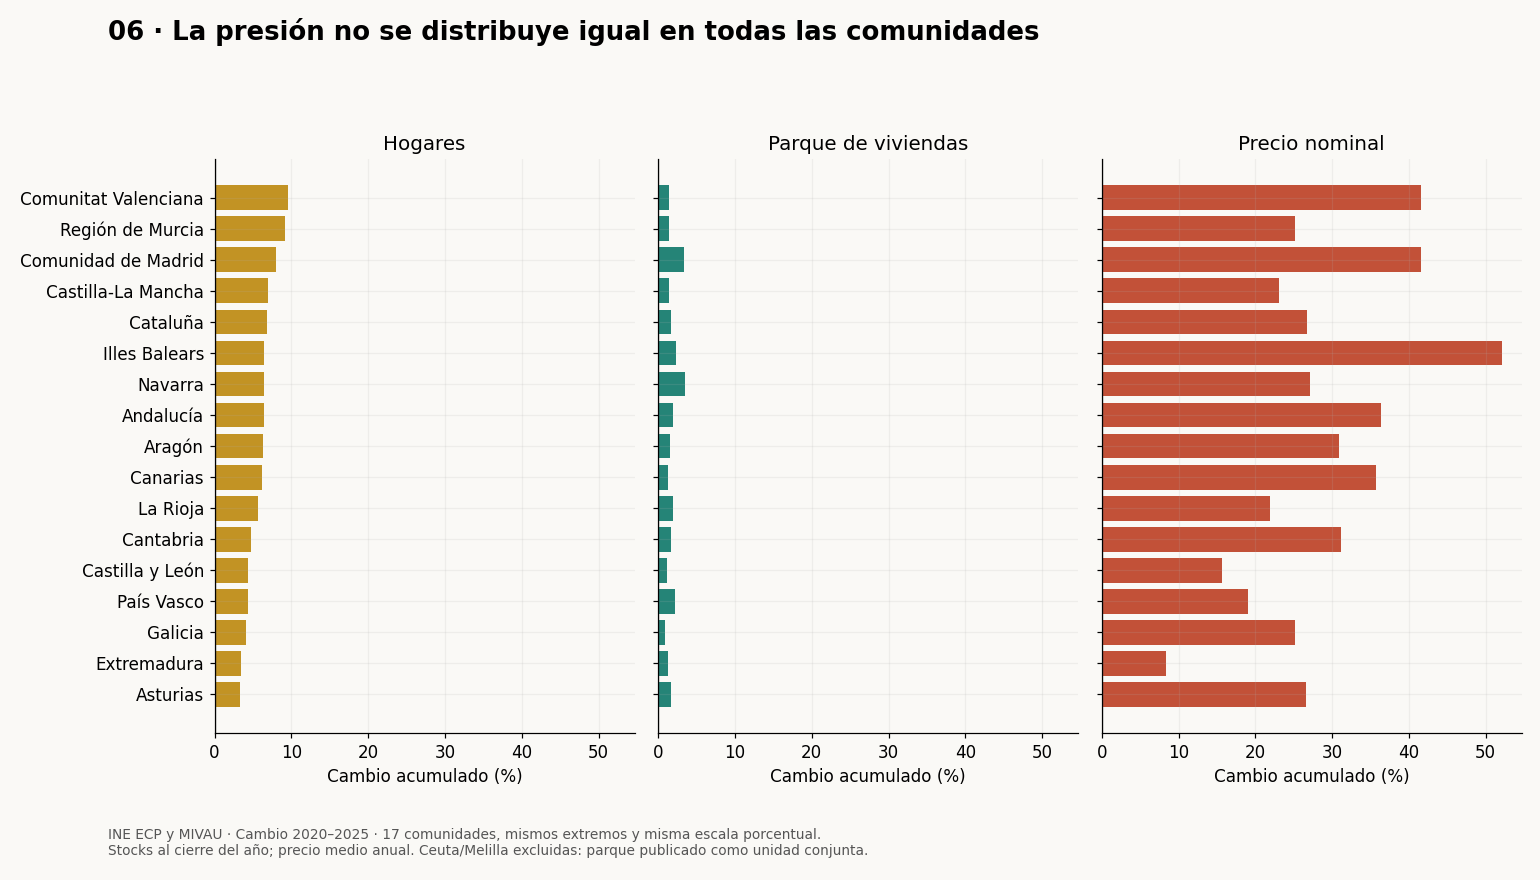

In [8]:
display(regional.sort_values("households_change_pct", ascending=False).round(2))
fig = make_figure(6, annual, birthplace, components, regional)
display(fig)
plt.close(fig)

## Resultados reproducibles y revisión de las afirmaciones

Las tablas y figuras se exportan con el mismo generador utilizado por el script. El resumen se calcula a partir de las observaciones, no de cifras escritas manualmente.

In [9]:
_, results = run_analysis(ROOT)
def spanish(value, decimals=0):
    return f"{value:,.{decimals}f}".replace(",", "X").replace(".", ",").replace("X", ".")
c = results["changes_pct"]
b = results["latest_components_per_1000"]
summary = f"""
- **2001–2025:** tasación nominal **+{spanish(c['price'], 1)}%**, población **+{spanish(c['population'], 1)}%**, adultos **+{spanish(c['adults'], 1)}%** y parque **+{spanish(c['dwellings'], 1)}%**. No crecen a la par; el parque crece más que la población en el periodo completo.
- **2021–2025:** se forman **{spanish(results['recent_net_household_formation'])} hogares netos** y se terminan **{spanish(results['recent_completions'])} viviendas**. La diferencia es **{spanish(results['recent_formation_minus_completions'])}**, un desajuste de estos dos flujos, no un déficit exacto. Se construye, pero estas entregas quedan por debajo de los nuevos hogares observados.
- **2024:** saldo natural **{spanish(b['natural_per_1000'], 2)}** y migratorio **+{spanish(b['migration_per_1000'], 2)}** por 1.000 habitantes. El saldo migratorio compensa el descenso natural. Esto respalda una contribución demográfica, sin medir su efecto en el precio.
- **2025, provisional:** residentes nacidos en España cambian en **{spanish(results['latest_change_born_spain'])}** y nacidos en el extranjero en **+{spanish(results['latest_change_born_abroad'])}**. Son cambios de grupos de residentes; no son recuentos de llegadas.
"""
display(Markdown(summary))


- **2001–2025:** tasación nominal **+120,0%**, población **+20,9%**, adultos **+23,9%** y parque **+28,8%**. No crecen a la par; el parque crece más que la población en el periodo completo.
- **2021–2025:** se forman **1.222.836 hogares netos** y se terminan **466.469 viviendas**. La diferencia es **756.367**, un desajuste de estos dos flujos, no un déficit exacto. Se construye, pero estas entregas quedan por debajo de los nuevos hogares observados.
- **2024:** saldo natural **-2,37** y migratorio **+12,81** por 1.000 habitantes. El saldo migratorio compensa el descenso natural. Esto respalda una contribución demográfica, sin medir su efecto en el precio.
- **2025, provisional:** residentes nacidos en España cambian en **-104.599** y nacidos en el extranjero en **+572.678**. Son cambios de grupos de residentes; no son recuentos de llegadas.


### Qué podemos concluir y qué queda abierto

| Afirmación | Evidencia de este bloque | Alcance |
|---|---|---|
| «No se construyen viviendas» | Hay viviendas iniciadas y terminadas todos los años observados | La frase literal no encaja; «se construye menos que nuevos hogares» sí puede contrastarse |
| «Las viviendas crecen menos que la población» | Revisar periodo completo y tramo reciente, ratios y hogares | No es una conclusión válida para cualquier periodo ni territorio |
| «La inmigración explica el aumento de residentes» | Saldos natural/migratorio y cambios por nacimiento | Evaluación demográfica anual; no equivale a explicar el precio |
| «La inmigración es la causa de la subida del precio» | Estas figuras no identifican ese efecto | Haría falta un diseño causal y considerar oferta, renta, empleo, crédito, turismo y migración interior |

La demanda de hogares puede aumentar con población estable por cambios en su tamaño o emancipación. La oferta de vivienda depende de localización, uso y accesibilidad, además del total construido. El análisis mantiene separadas estas relaciones y evita atribuir responsabilidad política o personal a partir de una coincidencia temporal.

**Reproducir:** `python scripts/run_block02.py` trabaja sin red. Para recuperar una nueva publicación, ejecutar explícitamente `python scripts/build_block02_data.py --refresh`, revisar cambios y volver a ejecutar el notebook. Los originales comprimidos, sus hashes, las tablas y seis PNG están versionados.